Importar bibliotecas

In [ ]:
import pandas as pd
from datetime import datetime
from datetime import timedelta
import matplotlib.pyplot as plt
import numpy as np
import math

In [ ]:
from google.colab import auth
auth.authenticate_user()

import gspread
from google.auth import default
creds, _ = default()

gc = gspread.authorize(creds)

Importar DF voluntarios

In [ ]:
#voluntarios_capitulo = pd.read_excel('/content/Current_Chapter_Members_with_Active_Volunteer_Role.xlsx', header=10)

Analise exploratoria

In [ ]:
#voluntarios_capitulo.info()

In [ ]:
#voluntarios_capitulo['PersonID'].nunique()

Importar DF membros_ativos

In [ ]:
membro_ativo = pd.read_excel('/content/Current_Month_Active_Members_List.xlsx', header=7)
membro_ativo.info()

/usr/local/lib/python3.11/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619 entries, 0 to 618
Data columns (total 14 columns):
 #   Column                                             Non-Null Count  Dtype         
---  ------                                             --------------  -----         
 0   Month(Chapter LoadYearMonth)                       619 non-null    datetime64[ns]
 1   Person ID                                          619 non-null    int64         
 2   First Name                                         619 non-null    object        
 3   Last Name                                          619 non-null    object        
 4   Primary Email                                      618 non-null    object        
 5   Chapter Join Date                                  619 non-null    datetime64[ns]
 6   Chapter Begin Date                                 619 non-null    datetime64[ns]
 7   Chapter Expiration Date                            619 non-null    datetime64[ns]
 8   Chapter Membership G

In [ ]:
membro_ativo = pd.read_excel(
    '/content/Current_Month_Active_Members_List.xlsx',
    header=7,
    usecols=['Month(Chapter LoadYearMonth)', 'Person ID', 'First Name', 'Last Name', 'Primary Email',
             'Chapter Join Date', 'Chapter Expiration Date',
             'Chapter Membership Group Code', 'Chapter Membership Group Name',
             'Chapter Membership Classification', 'Chapter Auto Renew Status',
             'Certification Status for Person', 'Unique Number of Count for Active Chapter Members']
)
membro_ativo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619 entries, 0 to 618
Data columns (total 13 columns):
 #   Column                                             Non-Null Count  Dtype         
---  ------                                             --------------  -----         
 0   Month(Chapter LoadYearMonth)                       619 non-null    datetime64[ns]
 1   Person ID                                          619 non-null    int64         
 2   First Name                                         619 non-null    object        
 3   Last Name                                          619 non-null    object        
 4   Primary Email                                      618 non-null    object        
 5   Chapter Join Date                                  619 non-null    datetime64[ns]
 6   Chapter Expiration Date                            619 non-null    datetime64[ns]
 7   Chapter Membership Group Code                      619 non-null    object        
 8   Chapter Membership G

In [ ]:
membro_ativo.head(15)

,Month(Chapter LoadYearMonth),Person ID,First Name,Last Name,Primary Email,Chapter Join Date,Chapter Expiration Date,Chapter Membership Group Code,Chapter Membership Group Name,Chapter Membership Classification,Chapter Auto Renew Status,Certification Status for Person,Unique Number of Count for Active Chapter Members
0,2025-01-01,753232,Mucio Leonardo Krapp,Tavares,Mucio.Tavares@hotmail.com,2007-03-07,2025-10-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,On,EXPIRED,1
1,2025-01-01,5224650,Geraldo Panitz,Ripoll,ripoll_ripoll@uol.com.br,2018-01-20,2026-01-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,NaN,ACTIVE,1
2,2025-01-01,10790229,Amanda,Da Silva Vicente de Moura,amandas.vicente@gmail.com,2024-09-27,2025-09-30,C192,"Rio de Janeiro, Brazil Chapter",Student,Off,NaN,1
3,2025-01-01,1502283,Ciro,Suetti,ciro.suetti@gmail.com,2009-04-21,2025-06-30,C192,"Rio de Janeiro, Brazil Chapter",Student,Off,ACTIVE,1
4,2025-01-01,1248815,GUILHERME,CALOBA,GCALOBA@YAHOO.COM.BR,2008-08-27,2025-08-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,On,ACTIVE,1
5,2025-01-01,2484662,Dimas,Tostes,dimas_tostes@hotmail.com,2012-08-24,2025-04-30,C192,"Rio de Janeiro, Brazil Chapter",Individual,On,ACTIVE,1
6,2025-01-01,10845244,Marcelo Henrique,Nepomuceno Silva,marcelonepomuceno@petrobras.com.br,2024-10-16,2025-10-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,On,NaN,1
7,2025-01-01,10194775,Flavio,Reis,flavio.pola@hc.fm.usp.br,2024-03-21,2025-03-31,C192,"Rio de Janeiro, Brazil Chapter",Student,Off,NaN,1
8,2025-01-01,8521675,Diego,Silva,d.diego.carneiro@gmail.com,2024-09-14,2025-09-30,C192,"Rio de Janeiro, Brazil Chapter",Student,Off,NaN,1
9,2025-01-01,2059430,André,Gil,andrelcgil@gmail.com,2011-04-11,2025-07-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,Out,ACTIVE,1


Analise exploratoria

In [ ]:
membro_ativo.head(15)

,Month(Chapter LoadYearMonth),Person ID,First Name,Last Name,Primary Email,Chapter Join Date,Chapter Expiration Date,Chapter Membership Group Code,Chapter Membership Group Name,Chapter Membership Classification,Chapter Auto Renew Status,Certification Status for Person,Unique Number of Count for Active Chapter Members
0,2025-01-01,753232,Mucio Leonardo Krapp,Tavares,Mucio.Tavares@hotmail.com,2007-03-07,2025-10-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,On,EXPIRED,1
1,2025-01-01,5224650,Geraldo Panitz,Ripoll,ripoll_ripoll@uol.com.br,2018-01-20,2026-01-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,NaN,ACTIVE,1
2,2025-01-01,10790229,Amanda,Da Silva Vicente de Moura,amandas.vicente@gmail.com,2024-09-27,2025-09-30,C192,"Rio de Janeiro, Brazil Chapter",Student,Off,NaN,1
3,2025-01-01,1502283,Ciro,Suetti,ciro.suetti@gmail.com,2009-04-21,2025-06-30,C192,"Rio de Janeiro, Brazil Chapter",Student,Off,ACTIVE,1
4,2025-01-01,1248815,GUILHERME,CALOBA,GCALOBA@YAHOO.COM.BR,2008-08-27,2025-08-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,On,ACTIVE,1
5,2025-01-01,2484662,Dimas,Tostes,dimas_tostes@hotmail.com,2012-08-24,2025-04-30,C192,"Rio de Janeiro, Brazil Chapter",Individual,On,ACTIVE,1
6,2025-01-01,10845244,Marcelo Henrique,Nepomuceno Silva,marcelonepomuceno@petrobras.com.br,2024-10-16,2025-10-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,On,NaN,1
7,2025-01-01,10194775,Flavio,Reis,flavio.pola@hc.fm.usp.br,2024-03-21,2025-03-31,C192,"Rio de Janeiro, Brazil Chapter",Student,Off,NaN,1
8,2025-01-01,8521675,Diego,Silva,d.diego.carneiro@gmail.com,2024-09-14,2025-09-30,C192,"Rio de Janeiro, Brazil Chapter",Student,Off,NaN,1
9,2025-01-01,2059430,André,Gil,andrelcgil@gmail.com,2011-04-11,2025-07-31,C192,"Rio de Janeiro, Brazil Chapter",Individual,Out,ACTIVE,1


In [ ]:
membro_ativo.columns= ['Chapter LoadYearMonth','Person ID','First Name','Last Name','Primary Email','Chapter Join Date', 'Chapter Expiration Date', 'Chapter Membership Group Code','Chapter Membership Group Name', 'Chapter Membership Classification', 'Chapter Auto Renew Status', 'Certification Status for Person', 'Unique Number of Count for Active Chapter Members']

In [ ]:
membro_ativo['Person ID'].nunique()

619

In [ ]:
membro_ativo['Primary Email'].nunique()

618

Analisar antiguidade

In [ ]:
membro_ativo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619 entries, 0 to 618
Data columns (total 13 columns):
 #   Column                                             Non-Null Count  Dtype         
---  ------                                             --------------  -----         
 0   Chapter LoadYearMonth                              619 non-null    datetime64[ns]
 1   Person ID                                          619 non-null    int64         
 2   First Name                                         619 non-null    object        
 3   Last Name                                          619 non-null    object        
 4   Primary Email                                      618 non-null    object        
 5   Chapter Join Date                                  619 non-null    datetime64[ns]
 6   Chapter Expiration Date                            619 non-null    datetime64[ns]
 7   Chapter Membership Group Code                      619 non-null    object        
 8   Chapter Membership G

In [ ]:
data_corte = datetime(2024, 1, 1)
membro_ativo['Antiguidade (anos)'] = (data_corte - membro_ativo['Chapter Join Date']).dt.days / 365.25
round(membro_ativo['Antiguidade (anos)'].describe(),2)

,Antiguidade (anos)
count,619.00
mean,5.97
std,7.71
min,-1.08
25%,-0.34
50%,1.05
75%,12.50
max,24.77


In [ ]:
mediana = membro_ativo['Antiguidade (anos)'].median()
anos = math.floor(mediana)
dias_restantes = (mediana - anos) * 365
meses = math.floor(dias_restantes / 30)
dias = round(dias_restantes % 30)
mediana_antiguidade_filiados = f"{anos} ano e {meses} meses"
print(mediana_antiguidade_filiados)

1 ano e 0 meses


ANTIGUIDADE QUE MAIS SE REPETE

In [ ]:
moda = membro_ativo['Antiguidade (anos)'].mode()
anos_moda = float(moda.iloc[0])

frequencia_moda = membro_ativo['Antiguidade (anos)'].value_counts().loc[anos_moda]

anos = math.floor(anos_moda)
dias_restantes_moda = (anos_moda - anos) * 365
meses_moda = math.floor(dias_restantes_moda / 30)
dias_moda = round(dias_restantes_moda % 30)

print(f"A antiguidade mais comum é: {anos} anos, {meses_moda} meses e {dias_moda} dias. Ela aparece {frequencia_moda} vezes.")

A antiguidade mais comum é: -1 anos, 9 meses e 15 dias. Ela aparece 65 vezes.


In [ ]:
total_membros_ativos = len(membro_ativo)
percentual_moda = round((frequencia_moda / total_membros_ativos) * 100, 2)
percentual_moda
print(f"A moda corresponde a {percentual_moda}% dos filiados ativos")

A moda corresponde a 10.5% dos filiados ativos


In [ ]:
antiguidade_maxima = membro_ativo['Antiguidade (anos)'].max()
antiguidade_maxima

24.772073921971252

Descobrir qtde filiacoes x mês em 2024

In [ ]:
membro_ativo_2024 = membro_ativo[membro_ativo['Chapter Join Date'].dt.year == 2024].copy()
filiacoes_por_mes = membro_ativo_2024.groupby(membro_ativo_2024['Chapter Join Date'].dt.month).size()
filiacoes_por_mes

,0
Chapter Join Date,
1,5
2,10
3,76
4,11
5,56
6,12
7,12
8,11
9,20


Separação de Membros em 2 categorias

*   Filiação Inicial
*   Filiação Renovada



In [ ]:
membro_ativo['Ciclo de Filiação'] = membro_ativo['Antiguidade (anos)'].apply(
    lambda x: (
        "Filiação Inicial" if x < 1
        else "Primeira Renovação" if 1 <= x < 2
        else "Filiação Consolidada"
    )
)

In [ ]:
membro_ativo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619 entries, 0 to 618
Data columns (total 15 columns):
 #   Column                                             Non-Null Count  Dtype         
---  ------                                             --------------  -----         
 0   Chapter LoadYearMonth                              619 non-null    datetime64[ns]
 1   Person ID                                          619 non-null    int64         
 2   First Name                                         619 non-null    object        
 3   Last Name                                          619 non-null    object        
 4   Primary Email                                      618 non-null    object        
 5   Chapter Join Date                                  619 non-null    datetime64[ns]
 6   Chapter Expiration Date                            619 non-null    datetime64[ns]
 7   Chapter Membership Group Code                      619 non-null    object        
 8   Chapter Membership G

In [ ]:
membro_ativo['Ciclo de Filiação'].value_counts()

,count
Ciclo de Filiação,
Filiação Inicial,308
Filiação Consolidada,289
Primeira Renovação,22


% Membros ativos em 2024 do total de ativos

In [ ]:
total_membros_ativos_2024 = len(membro_ativo_2024)
round((total_membros_ativos_2024 / total_membros_ativos),2) * 100

41.0

Filiações que irão expirar em 2025 x Mês

In [ ]:
membros_expiracao_2025 = membro_ativo[
    (membro_ativo['Chapter Expiration Date'].dt.year == 2025) &
    (membro_ativo['Chapter Auto Renew Status'] != 'On')
].copy()
membros_expiracao_2025['Mês de Expiração'] = membros_expiracao_2025['Chapter Expiration Date'].dt.month
expiracao_por_mes = membros_expiracao_2025.groupby('Mês de Expiração').size()
expiracao_por_mes

,0
Mês de Expiração,
1,16
2,16
3,82
4,15
5,66
6,14
7,12
8,33
9,32


Membros com renovação automatica

In [ ]:
membro_ativo['Chapter Auto Renew Status'] = membro_ativo['Chapter Auto Renew Status'].apply(
    lambda x: 'On' if x == 'On' else 'Off'
)
membro_ativo['Chapter Auto Renew Status'].value_counts()

,count
Chapter Auto Renew Status,
Off,384
On,235


Membros certificados

In [ ]:
certification_map = {
    'ACTIVE': 'Ativa',
    'EXPIRED': 'Expirada'
}

membro_ativo['Certification Status for Person'] = membro_ativo['Certification Status for Person'].replace(certification_map, regex=True)

membro_ativo['Certification Status for Person'].value_counts()

,count
Certification Status for Person,
Ativa,319
Expirada,11


In [ ]:
membro_ativo['Certification Status for Person'].fillna('Desconhecida', inplace=True)
membro_ativo['Certification Status for Person'].value_counts()

<ipython-input-39-bb6e4576ddea>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  membro_ativo['Certification Status for Person'].fillna('Desconhecida', inplace=True)


,count
Certification Status for Person,
Ativa,319
Desconhecida,289
Expirada,11


In [ ]:
classification_map = {
    'Individual': 'Individual',
    'Student': 'Estudante',
    'Retiree': 'Aposentado'
}

membro_ativo['Chapter Membership Classification'] = membro_ativo['Chapter Membership Classification'].replace(classification_map, regex=True)

membro_ativo['Chapter Membership Classification'].value_counts()

,count
Chapter Membership Classification,
Individual,437
Estudante,176
Aposentado,6


Importar DataFrame n_renovados para identificar perfil de filiados que não renovaram a filiação

In [ ]:
#n_renovados = pd.read_excel('/content/Current_Month_NonRenewals_List.xlsx', header=5)
#n_renovados.info()

In [ ]:
#n_renovados['Total Count for Chapter Member NonRenewals'].max()

Quantos receberam notificação eletronica

In [ ]:
#n_renovados['Receive Electronic Notification'].value_counts()

Qual industria dos não renovados

In [ ]:
#n_renovados['Industry Type'].value_counts()

Status das certificações

In [ ]:
#n_renovados['PMP Status'].value_counts()

Importar DataFrame renovados para identificar perfil de filiados que renovaram a filiação

In [ ]:
#renovados = pd.read_excel('/content/Current_Month_Renewals_List.xlsx', header=5)
#renovados.info()

In [ ]:
#renovados['Total Count for Chapter Member Renewals'].max()

In [ ]:
#renovacao_automatica = renovados[renovados['Chapter Auto Renew Status'] == 'On']
#len(renovacao_automatica)

In [ ]:
#renovados['PMP Status'].value_counts()

In [ ]:
membro_ativo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619 entries, 0 to 618
Data columns (total 15 columns):
 #   Column                                             Non-Null Count  Dtype         
---  ------                                             --------------  -----         
 0   Chapter LoadYearMonth                              619 non-null    datetime64[ns]
 1   Person ID                                          619 non-null    int64         
 2   First Name                                         619 non-null    object        
 3   Last Name                                          619 non-null    object        
 4   Primary Email                                      618 non-null    object        
 5   Chapter Join Date                                  619 non-null    datetime64[ns]
 6   Chapter Expiration Date                            619 non-null    datetime64[ns]
 7   Chapter Membership Group Code                      619 non-null    object        
 8   Chapter Membership G

In [ ]:
membro_ativo['Complete_Name'] = membro_ativo['First Name'] + ' ' + membro_ativo['Last Name']
membro_ativo['Complete_Name'] = membro_ativo['Complete_Name'].str.title()

In [ ]:
columns = ['Person ID','Complete_Name', 'Primary Email', 'Chapter Join Date', 'Chapter Expiration Date', 'Chapter Membership Classification', 'Chapter Auto Renew Status', 'Certification Status for Person', 'Ciclo de Filiação' ]
export_membro_ativo = membro_ativo[columns]
export_membro_ativo.columns= ['ID','Nome Completo','Email','Data Filiação','Data Expiração','Classificação','Renovação Automarica', 'Certificação', 'Ciclo de Filiação']
export_membro_ativo

,ID,Nome Completo,Email,Data Filiação,Data Expiração,Classificação,Renovação Automarica,Certificação,Ciclo de Filiação
0,753232,Mucio Leonardo Krapp Tavares,Mucio.Tavares@hotmail.com,2007-03-07,2025-10-31,Individual,On,Expirada,Filiação Consolidada
1,5224650,Geraldo Panitz Ripoll,ripoll_ripoll@uol.com.br,2018-01-20,2026-01-31,Individual,Off,Ativa,Filiação Consolidada
2,10790229,Amanda Da Silva Vicente De Moura,amandas.vicente@gmail.com,2024-09-27,2025-09-30,Estudante,Off,Desconhecida,Filiação Inicial
3,1502283,Ciro Suetti,ciro.suetti@gmail.com,2009-04-21,2025-06-30,Estudante,Off,Ativa,Filiação Consolidada
4,1248815,Guilherme Caloba,GCALOBA@YAHOO.COM.BR,2008-08-27,2025-08-31,Individual,On,Ativa,Filiação Consolidada
...,...,...,...,...,...,...,...,...,...
614,2434154,Tiago Correa,tiagojnc@gmail.com,2012-07-02,2025-08-31,Individual,Off,Ativa,Filiação Consolidada
615,10393128,Felipe Leandro Lima,felipe.maurilo@fendercare.com,2024-05-29,2025-05-31,Estudante,Off,Desconhecida,Filiação Inicial
616,2206212,Carlos Ribeiro,carlosaffonso@uol.com.br,2011-10-06,2025-05-31,Individual,Off,Ativa,Filiação Consolidada
617,2513882,Gustavo Sarruf Estefan,gsarruf@uol.com.br,2013-02-06,2025-02-28,Individual,Off,Ativa,Filiação Consolidada


In [ ]:
spreadsheet_key = '1Hul3w2TUCvOL7ShW4qq0OFlLUMYFNYQJB6bMYnIiSb4'
worksheet_name = 'dados'
worksheet = gc.open_by_key(spreadsheet_key).worksheet(worksheet_name)

worksheet.clear()

{'spreadsheetId': '1Hul3w2TUCvOL7ShW4qq0OFlLUMYFNYQJB6bMYnIiSb4',
 'clearedRange': 'dados!A1:Z1000'}

In [ ]:
export_membro_ativo = export_membro_ativo.replace([np.inf, -np.inf], np.nan)

data_to_write = [[str(cell) if not pd.isnull(cell) else '' for cell in row] for row in export_membro_ativo.values.tolist()]

worksheet.update([export_membro_ativo.columns.values.tolist()] + data_to_write, value_input_option='USER_ENTERED')

print("Dados atualizados com sucesso!")

Dados atualizados com sucesso!


## Visualização dos dados

In [ ]:
membro_ativo['Person ID'].nunique()

619

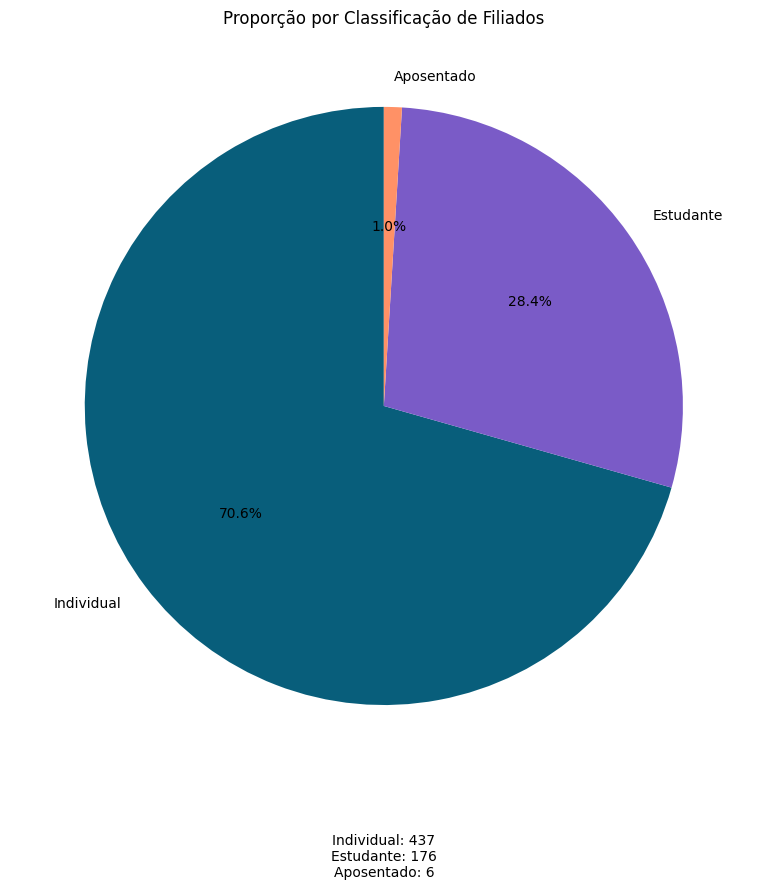

In [ ]:
classificacao_membros = membro_ativo['Chapter Membership Classification'].value_counts()

plt.figure(figsize=(8, 8))
classificacao_membros.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', '#7a5bc7', '#ff9166'],
    title="Proporção por Classificação de Filiados"
)
plt.ylabel('')

observacoes = "\n".join([f"{classe}: {quantidade}" for classe, quantidade in classificacao_membros.items()])
plt.figtext(
    0.5,
    -0.1,
    observacoes,
    wrap=True,
    horizontalalignment='center',
    fontsize=10,
    color='black'
)

plt.tight_layout()
plt.show()

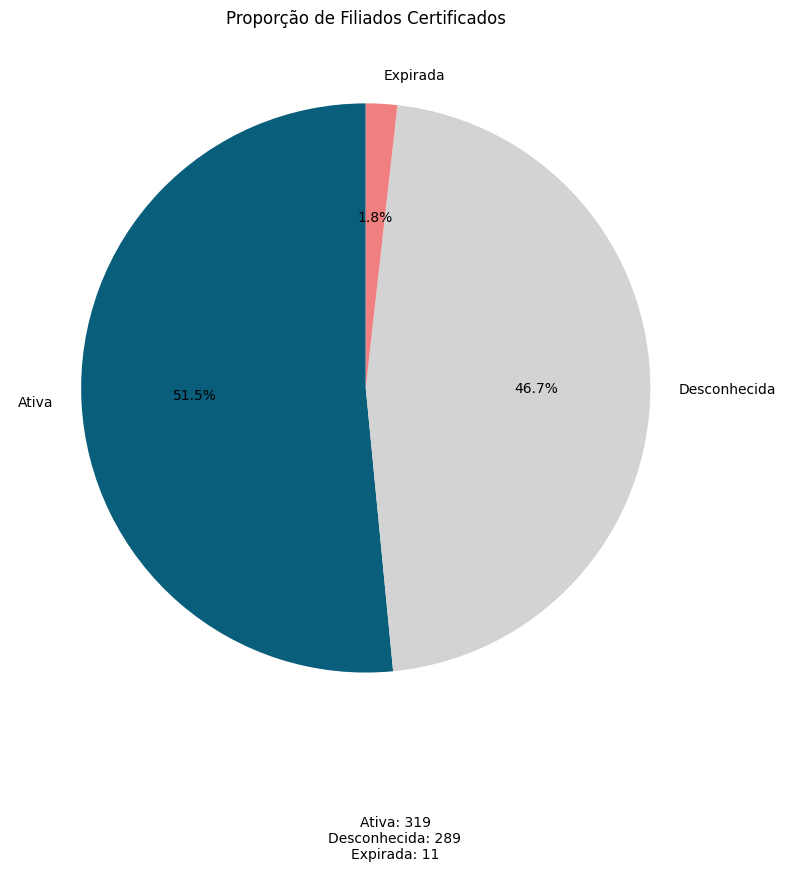

In [ ]:
certificados_status = membro_ativo['Certification Status for Person'].value_counts()

cores = ['#085e7b', 'lightgray', 'lightcoral', 'lightgreen', 'khaki']

plt.figure(figsize=(8, 8))
certificados_status.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=cores,
    title="Proporção de Filiados Certificados"
)
plt.ylabel('')

observacoes = "\n".join([f"{status}: {quantidade}" for status, quantidade in certificados_status.items()])
plt.figtext(
    0.5,
    -0.1,
    observacoes,
    wrap=True,
    horizontalalignment='center',
    fontsize=10,
    color='black'
)

plt.tight_layout()
plt.show()

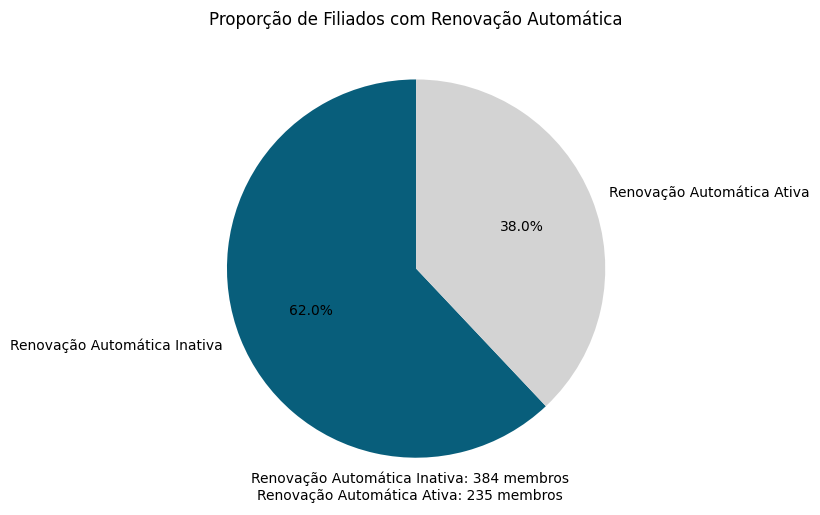

In [ ]:
status_renovacao = membro_ativo['Chapter Auto Renew Status'].value_counts()

dados = [status_renovacao['Off'], status_renovacao['On']]
labels = ['Renovação Automática Inativa', 'Renovação Automática Ativa']
cores = ['#085e7b', 'lightgray']

plt.figure(figsize=(8, 8))
plt.pie(dados, labels=labels, autopct='%1.1f%%', startangle=90, colors=cores)
plt.title("Proporção de Filiados com Renovação Automática")

observacoes = f"Renovação Automática Inativa: {status_renovacao['Off']} membros\nRenovação Automática Ativa: {status_renovacao['On']} membros"
plt.figtext(
    0.5,
    0.2,
    observacoes,
    wrap=True,
    horizontalalignment='center',
    fontsize=10,
    color='black'
)

plt.tight_layout()
plt.show()


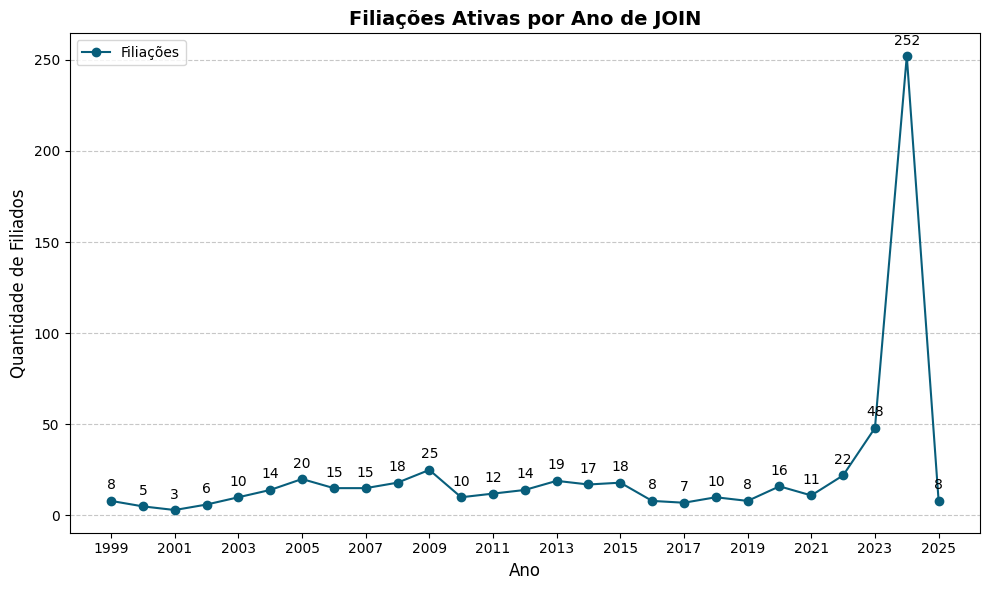

In [ ]:
filiacoes_por_ano = membro_ativo.groupby(membro_ativo['Chapter Join Date'].dt.year).size()

plt.figure(figsize=(10, 6))
plt.plot(filiacoes_por_ano.index, filiacoes_por_ano.values, marker='o', linestyle='-', color='#085e7b', label='Filiações')

for x, y in zip(filiacoes_por_ano.index, filiacoes_por_ano.values):
    plt.text(x, y + max(filiacoes_por_ano.values) * 0.025, str(y), fontsize=10, ha='center', color='black')

min_year = filiacoes_por_ano.index.min()
max_year = filiacoes_por_ano.index.max()
plt.xticks(ticks=np.arange(min_year, max_year + 1, 2), fontsize=10)

plt.title("Filiações Ativas por Ano de JOIN", fontsize=14, fontweight='bold')
plt.xlabel("Ano", fontsize=12)
plt.ylabel("Quantidade de Filiados", fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

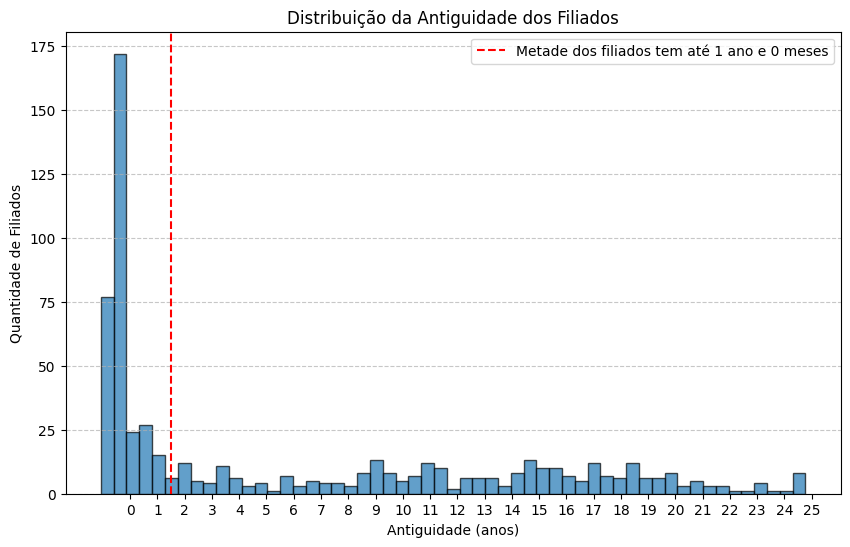

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(membro_ativo['Antiguidade (anos)'], bins=55, edgecolor='black', alpha=0.7)
plt.axvline(1.48, color='red', linestyle='--', label=f'Metade dos filiados tem até {mediana_antiguidade_filiados}')
plt.title("Distribuição da Antiguidade dos Filiados")
plt.xlabel("Antiguidade (anos)")
plt.ylabel("Quantidade de Filiados")

max_valor = membro_ativo['Antiguidade (anos)'].max()
plt.xticks(np.arange(0, max_valor + 1, 1))

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

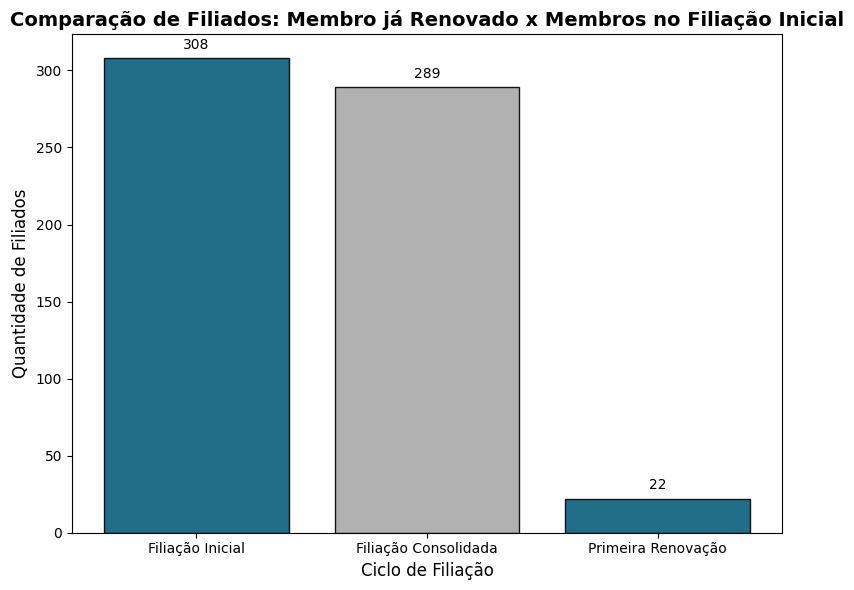

In [ ]:
status_counts = membro_ativo['Ciclo de Filiação'].value_counts()

plt.figure(figsize=(8, 6))
plt.bar(status_counts.index, status_counts.values, color=['#085e7b', 'darkgray'], alpha=0.9, edgecolor='black')

plt.title("Comparação de Filiados: Membro já Renovado x Membros no Filiação Inicial", fontsize=14, fontweight='bold')
plt.xlabel("Ciclo de Filiação", fontsize=12)
plt.ylabel("Quantidade de Filiados", fontsize=12)

for i, v in enumerate(status_counts.values):
    plt.text(i, v + max(status_counts.values) * 0.02, str(v), fontsize=10, ha='center', color='black')

plt.tight_layout()
plt.show()

MEMBROS RENOVADOS

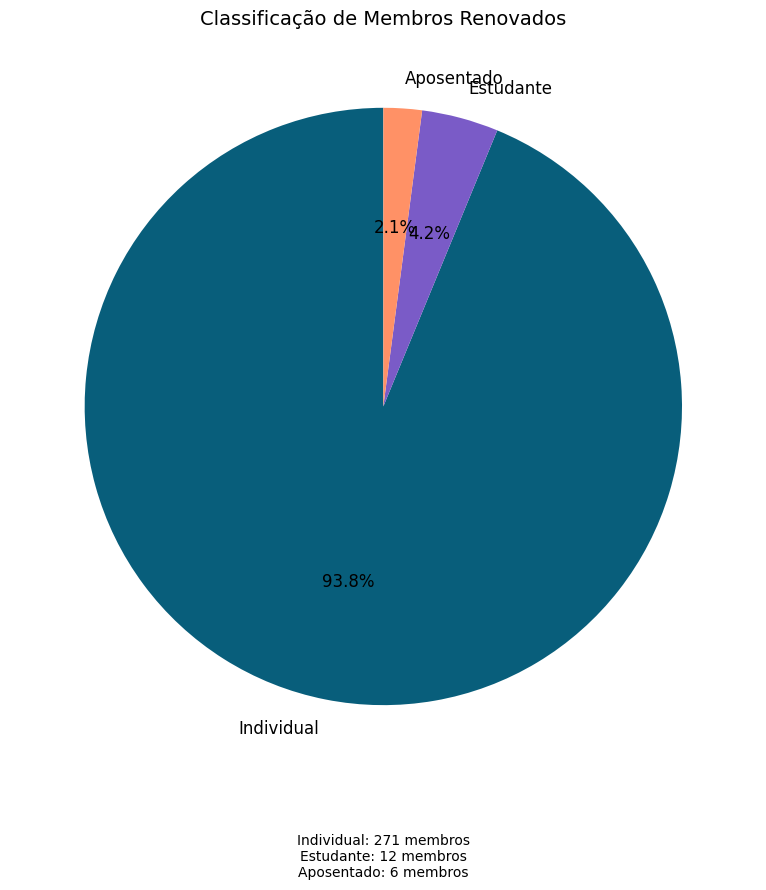

In [ ]:
membros_renovados = membro_ativo[membro_ativo['Ciclo de Filiação'] == 'Filiação Consolidada']

classification_counts = membros_renovados['Chapter Membership Classification'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    classification_counts.values,
    labels=classification_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', '#7a5bc7', '#ff9166'],
    textprops={'fontsize': 12}
)

plt.title("Classificação de Membros Renovados", fontsize=14)

observacoes = "\n".join([f"{classe}: {quantidade} membros" for classe, quantidade in classification_counts.items()])
plt.figtext(
    0.5,
    -0.1,
    observacoes,
    wrap=True,
    horizontalalignment='center',
    fontsize=10,
    color='black'
)

plt.tight_layout()
plt.show()


In [ ]:
"""
renovados_por_renovacao = membros_renovados['Chapter Auto Renew Status'].value_counts()

percentuais = (renovados_por_renovacao / renovados_por_renovacao.sum()) * 100

plt.figure(figsize=(8, 6))
bars = plt.bar(
    renovados_por_renovacao.index,
    renovados_por_renovacao.values,
    color=['#085e7b', 'darkgray'],
    alpha=0.9,
    edgecolor='black'
)

plt.title("Quantidade de Renovados com e sem Renovação Automática", fontsize=14, fontweight='bold')
plt.xlabel("Status de Renovação Automática", fontsize=12)
plt.ylabel("Quantidade de Renovados", fontsize=12)

for bar, count, pct in zip(bars, renovados_por_renovacao.values, percentuais):
    plt.text(bar.get_x() + bar.get_width() / 2, count + 5, f'{count}', fontsize=10, ha='center', color='black')

    plt.text(bar.get_x() + bar.get_width() / 2, count / 2, f'{pct:.1f}%', fontsize=10, ha='center', color='black')

plt.tight_layout()
plt.show()
"""

'\nrenovados_por_renovacao = membros_renovados[\'Chapter Auto Renew Status\'].value_counts()\n\npercentuais = (renovados_por_renovacao / renovados_por_renovacao.sum()) * 100\n\nplt.figure(figsize=(8, 6))\nbars = plt.bar(\n    renovados_por_renovacao.index,\n    renovados_por_renovacao.values,\n    color=[\'#085e7b\', \'darkgray\'],\n    alpha=0.9,\n    edgecolor=\'black\'\n)\n\nplt.title("Quantidade de Renovados com e sem Renovação Automática", fontsize=14, fontweight=\'bold\')\nplt.xlabel("Status de Renovação Automática", fontsize=12)\nplt.ylabel("Quantidade de Renovados", fontsize=12)\n\nfor bar, count, pct in zip(bars, renovados_por_renovacao.values, percentuais):\n    plt.text(bar.get_x() + bar.get_width() / 2, count + 5, f\'{count}\', fontsize=10, ha=\'center\', color=\'black\')\n\n    plt.text(bar.get_x() + bar.get_width() / 2, count / 2, f\'{pct:.1f}%\', fontsize=10, ha=\'center\', color=\'black\')\n\nplt.tight_layout()\nplt.show()\n'

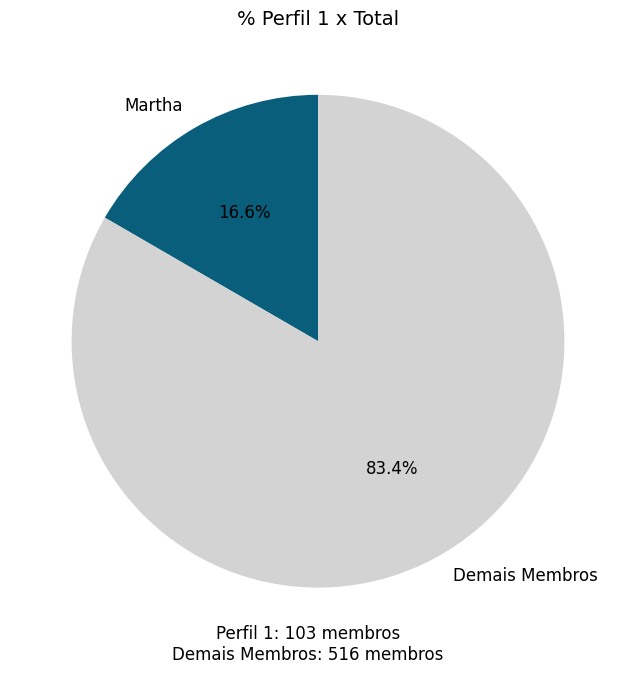

In [ ]:
perfil_1 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Filiação Consolidada') &
    (membro_ativo['Chapter Membership Classification'] == 'Individual') &
    (membro_ativo['Chapter Auto Renew Status'] == 'On') &
    (membro_ativo['Certification Status for Person'] == 'Ativa')
]

perfil_count = len(perfil_1)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Martha', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("% Perfil 1 x Total", fontsize=14)

plt.figtext(
    0.5,
    0.1,
    f"Perfil 1: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

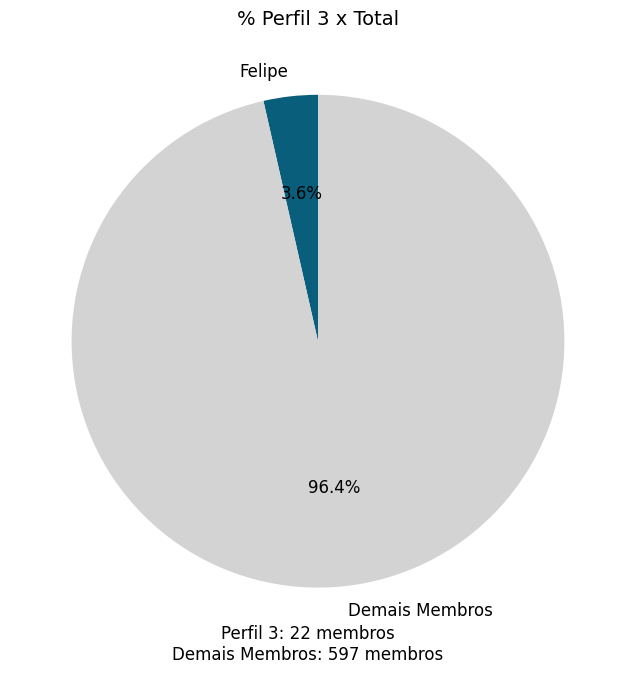

In [ ]:
perfil_3 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Primeira Renovação')
]

perfil_count = len(perfil_3)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Felipe', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("% Perfil 3 x Total", fontsize=14)

plt.figtext(
    0.5,
    0.1,
    f"Perfil 3: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

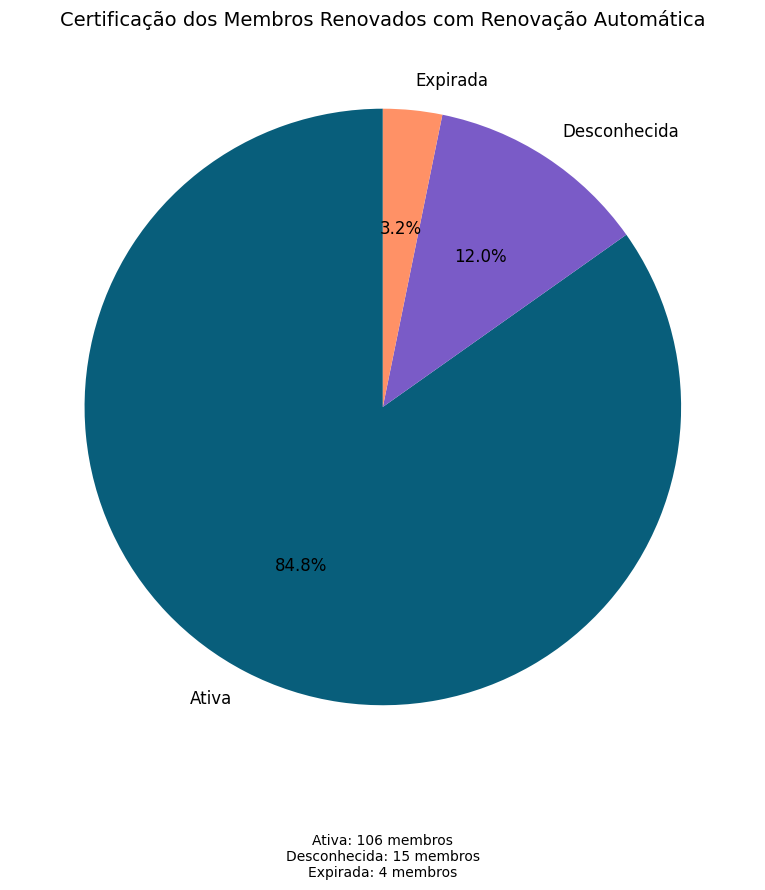

In [ ]:
membros_sem_renovacao_automatica = membros_renovados[membros_renovados['Chapter Auto Renew Status'] == 'On']

certificacao_counts = membros_sem_renovacao_automatica['Certification Status for Person'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    certificacao_counts.values,
    labels=certificacao_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', '#7a5bc7', '#ff9166'],
    textprops={'fontsize': 12}
)

plt.title("Certificação dos Membros Renovados com Renovação Automática", fontsize=14)

observacoes = "\n".join([f"{status}: {quantidade} membros" for status, quantidade in certificacao_counts.items()])
plt.figtext(
    0.5,
    -0.1,
    observacoes,
    wrap=True,
    horizontalalignment='center',
    fontsize=10,
    color='black'
)

plt.tight_layout()
plt.show()


# PRIMEIRO SUB-PERFIL

<ipython-input-67-cdbef7698802>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  membros_filtrados['Antiguidade (Categoria)'] = pd.cut(


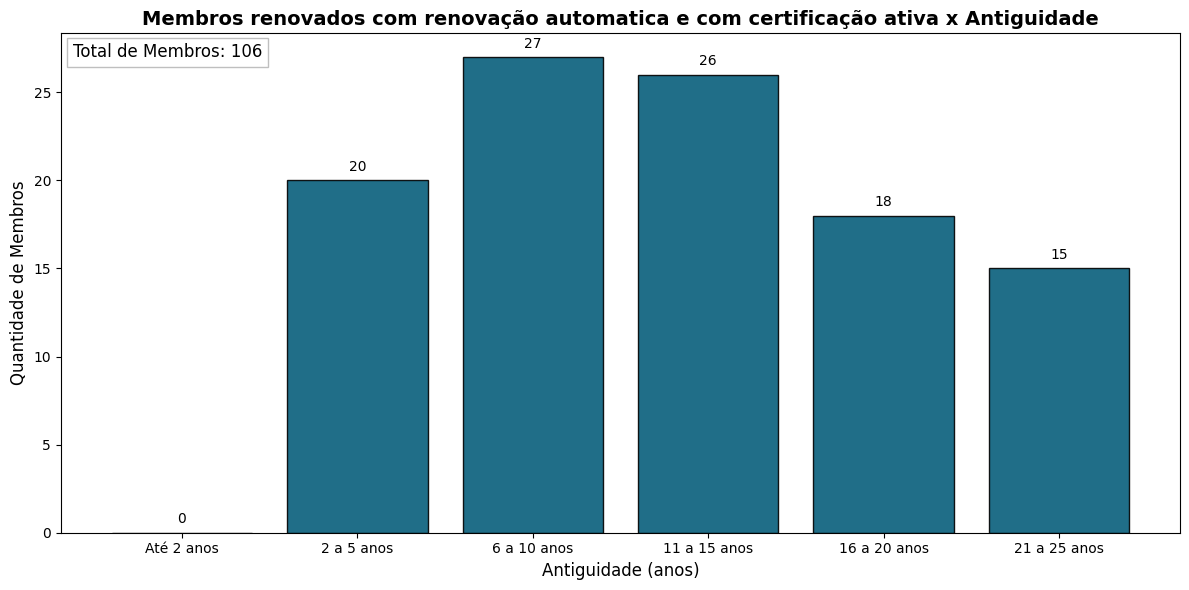

In [ ]:
membros_filtrados = membros_renovados[(membros_renovados['Chapter Auto Renew Status'] == 'On') &
    (membros_renovados['Certification Status for Person'] == 'Ativa')
]

bins = [0, 2, 5, 10, 15, 20, 25]
labels = ['Até 2 anos', '2 a 5 anos', '6 a 10 anos', '11 a 15 anos', '16 a 20 anos', '21 a 25 anos']

membros_filtrados['Antiguidade (Categoria)'] = pd.cut(
    membros_filtrados['Antiguidade (anos)'], bins=bins, labels=labels, include_lowest=True
)

antiguidade_grouped = membros_filtrados['Antiguidade (Categoria)'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
bars = plt.bar(antiguidade_grouped.index, antiguidade_grouped.values, color='#085e7b', alpha=0.9, edgecolor='black')

plt.title("Membros renovados com renovação automatica e com certificação ativa x Antiguidade", fontsize=14, fontweight='bold')
plt.xlabel("Antiguidade (anos)", fontsize=12)
plt.ylabel("Quantidade de Membros", fontsize=12)

for bar, value in zip(bars, antiguidade_grouped.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + max(antiguidade_grouped.values) * 0.02, str(value), fontsize=10, ha='center', color='black')

total_grouped = antiguidade_grouped.sum()
plt.text(
    0.18,
    0.98,
    f"Total de Membros: {total_grouped}",
    fontsize=12,
    ha='right',
    va='top',
    transform=plt.gca().transAxes,
    bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray')
)

plt.tight_layout()
plt.show()

PRIMEIRO SUB PERFIL:
Filiação Renovada, CLASSIFICAÇÃO INDIVIDUAL, A RENOVAÇÃO AUTOMATICA ESTÁ ATIVA, É CERTIFICADO E TEM ENTRE 6 E 20 ANOS DE FILIAÇÃO

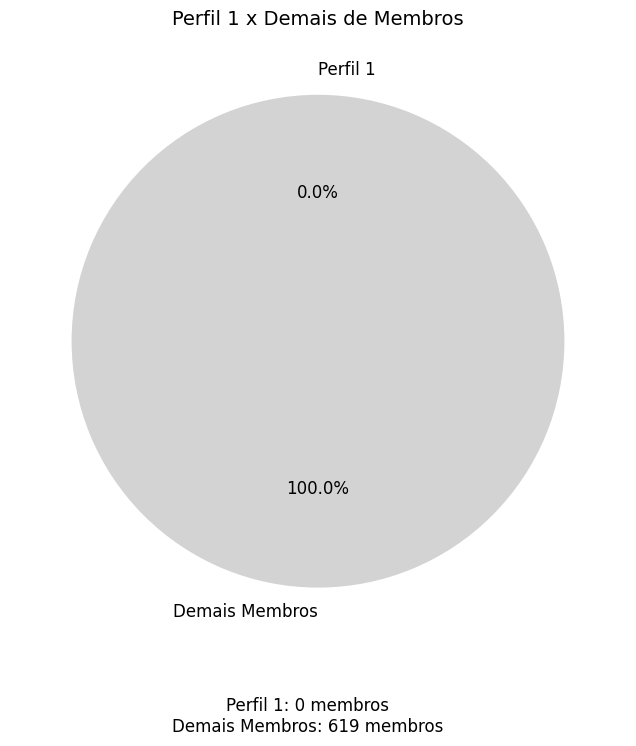

In [ ]:
perfil_1 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Filiação Renovada') &
    (membro_ativo['Chapter Membership Classification'] == 'Individual') &
    (membro_ativo['Chapter Auto Renew Status'] == 'On') &
    (membro_ativo['Certification Status for Person'] == 'Ativa') &
    (membro_ativo['Antiguidade (anos)'].between(6, 20))
]

perfil_count = len(perfil_1)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Perfil 1', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("Perfil 1 x Demais de Membros", fontsize=14)

plt.figtext(
    0.5,
    0.01,
    f"Perfil 1: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

# SEGUNDO PERFIL

<ipython-input-69-cafb852edaa3>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  membros_filtrados['Antiguidade (Categoria)'] = pd.cut(


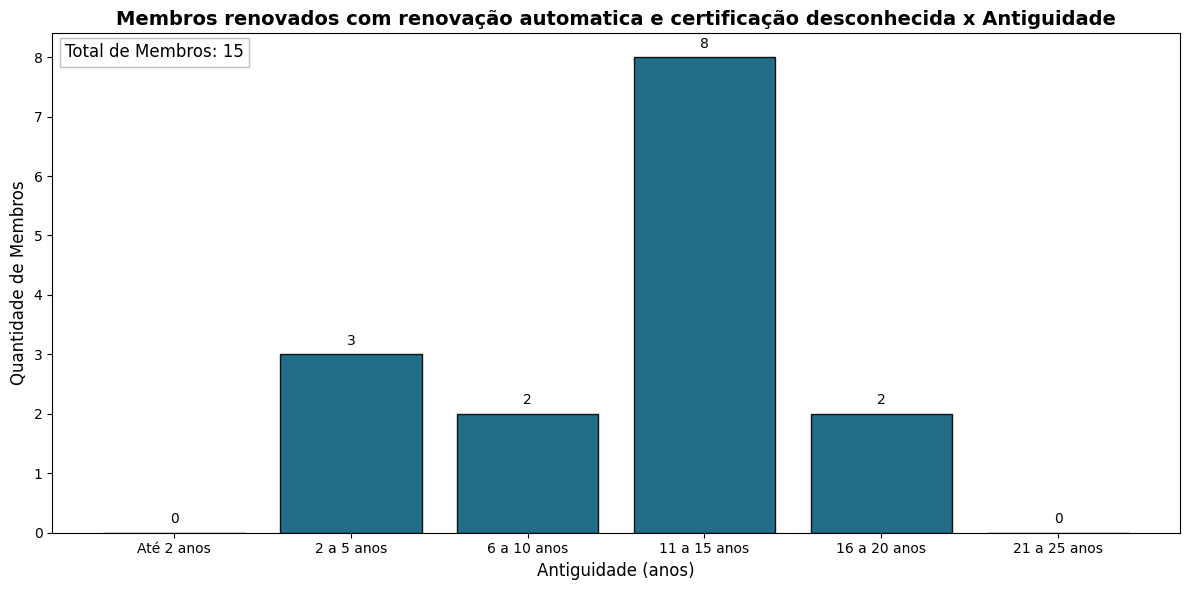

In [ ]:
membros_filtrados = membros_renovados[
    (membros_renovados['Chapter Auto Renew Status'] == 'On') &
    (membros_renovados['Certification Status for Person'] == 'Desconhecida')
]

bins = [0, 2, 5, 10, 15, 20, 25]
labels = ['Até 2 anos', '2 a 5 anos', '6 a 10 anos', '11 a 15 anos', '16 a 20 anos', '21 a 25 anos']

membros_filtrados['Antiguidade (Categoria)'] = pd.cut(
    membros_filtrados['Antiguidade (anos)'], bins=bins, labels=labels, include_lowest=True
)

antiguidade_grouped = membros_filtrados['Antiguidade (Categoria)'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
bars = plt.bar(antiguidade_grouped.index, antiguidade_grouped.values, color='#085e7b', alpha=0.9, edgecolor='black')

plt.title("Membros renovados com renovação automatica e certificação desconhecida x Antiguidade", fontsize=14, fontweight='bold')
plt.xlabel("Antiguidade (anos)", fontsize=12)
plt.ylabel("Quantidade de Membros", fontsize=12)

for bar, value in zip(bars, antiguidade_grouped.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + max(antiguidade_grouped.values) * 0.02, str(value), fontsize=10, ha='center', color='black')

total_grouped = antiguidade_grouped.sum()
plt.text(
    0.17,
    0.98,
    f"Total de Membros: {total_grouped}",
    fontsize=12,
    ha='right',
    va='top',
    transform=plt.gca().transAxes,
    bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray')
)

plt.tight_layout()
plt.show()

SEGUNDO PERFIL:
Filiação Renovada, CLASSIFICAÇÃO INDIVIDUAL, A RENOVAÇÃO AUTOMATICA ESTÁ ATIVA, NÃO É CERTIFICADO E TEM ENTRE 11 E 25 ANOS DE FILIAÇÃO

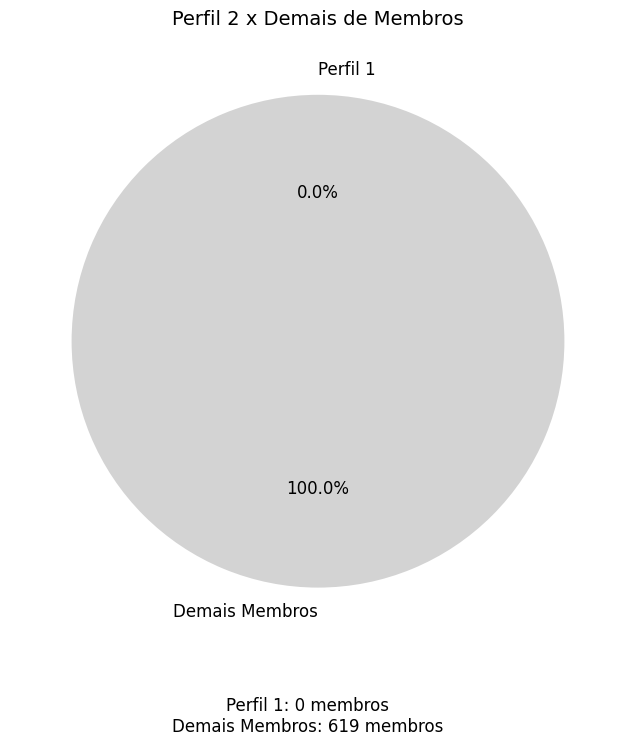

In [ ]:
perfil_2 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Filiação Renovada') &
    (membro_ativo['Chapter Membership Classification'] == 'Individual') &
    (membro_ativo['Chapter Auto Renew Status'] == 'On') &
    (membro_ativo['Certification Status for Person'] == 'Desconhecida') &
    (membro_ativo['Antiguidade (anos)'].between(11, 25))
]

perfil_count = len(perfil_2)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Perfil 1', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("Perfil 2 x Demais de Membros", fontsize=14)

plt.figtext(
    0.5,
    0.01,
    f"Perfil 1: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

# SEGUNDO PERFIL GERAL

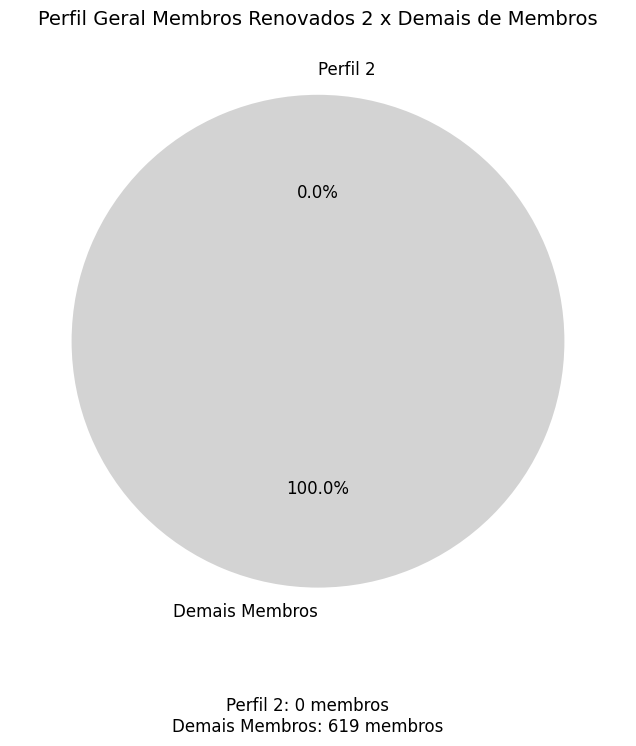

In [ ]:
perfil_2 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Filiação Renovada') &
    (membro_ativo['Chapter Auto Renew Status'] == 'Off')
]

perfil_count = len(perfil_2)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Perfil 2', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("Perfil Geral Membros Renovados 2 x Demais de Membros", fontsize=14)

plt.figtext(
    0.5,
    0.01,
    f"Perfil 2: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

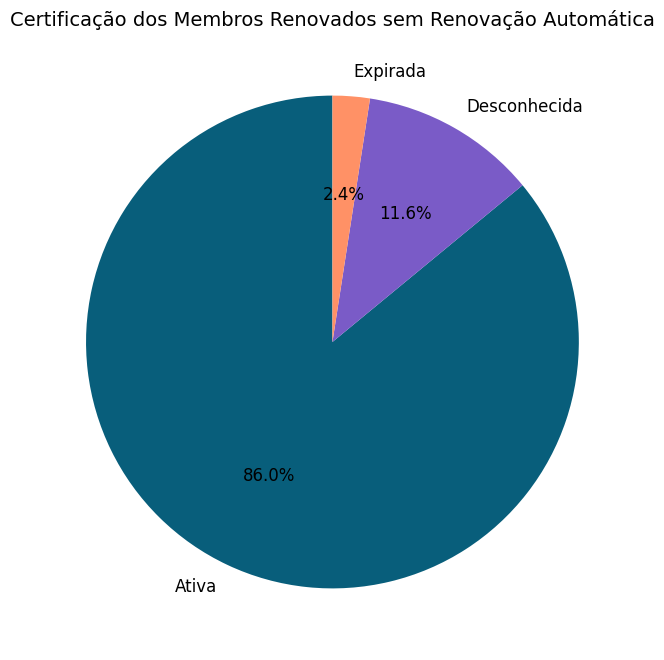

In [ ]:
membros_sem_renovacao_automatica = membros_renovados[membros_renovados['Chapter Auto Renew Status'] == 'Off']

certificacao_counts = membros_sem_renovacao_automatica['Certification Status for Person'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    certificacao_counts.values,
    labels=certificacao_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', '#7a5bc7', '#ff9166'],
    textprops={'fontsize': 12}
)

plt.title("Certificação dos Membros Renovados sem Renovação Automática", fontsize=14)
plt.show()

<ipython-input-73-4fc751fa98c5>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  membros_filtrados['Antiguidade (Categoria)'] = pd.cut(


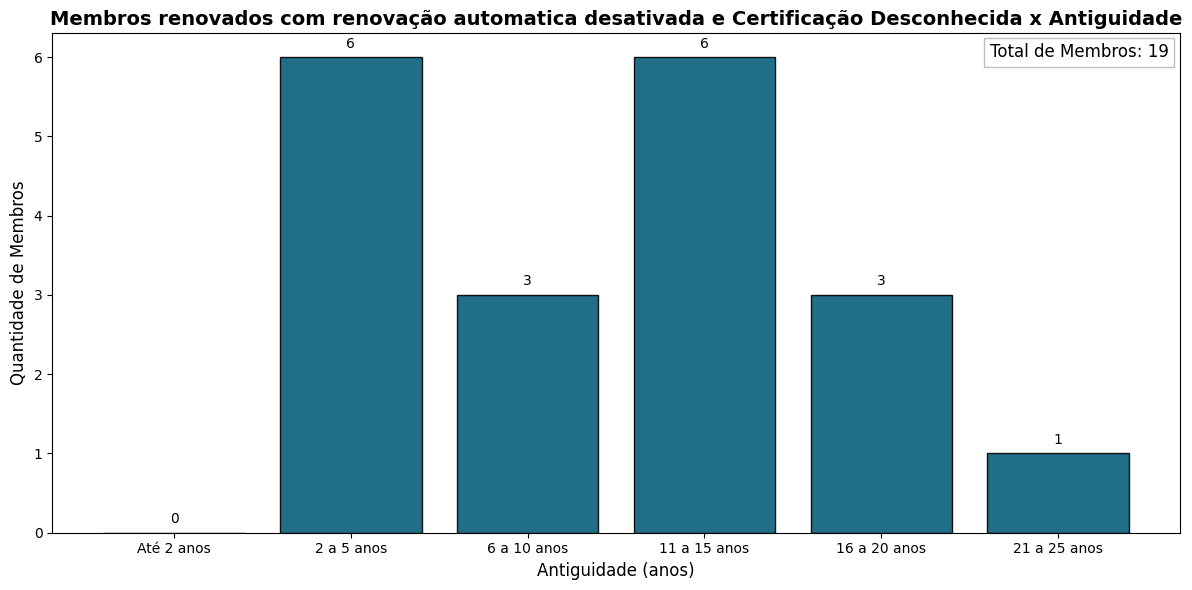

In [ ]:
membros_filtrados = membros_renovados[
    (membros_renovados['Chapter Auto Renew Status'] == 'Off') &
    (membros_renovados['Certification Status for Person'] == 'Desconhecida')
]

bins = [0, 2, 5, 10, 15, 20, 25]
labels = ['Até 2 anos', '2 a 5 anos', '6 a 10 anos', '11 a 15 anos', '16 a 20 anos', '21 a 25 anos']

membros_filtrados['Antiguidade (Categoria)'] = pd.cut(
    membros_filtrados['Antiguidade (anos)'], bins=bins, labels=labels, include_lowest=True
)

antiguidade_grouped = membros_filtrados['Antiguidade (Categoria)'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
bars = plt.bar(antiguidade_grouped.index, antiguidade_grouped.values, color='#085e7b', alpha=0.9, edgecolor='black')

plt.title("Membros renovados com renovação automatica desativada e Certificação Desconhecida x Antiguidade", fontsize=14, fontweight='bold')
plt.xlabel("Antiguidade (anos)", fontsize=12)
plt.ylabel("Quantidade de Membros", fontsize=12)

for bar, value in zip(bars, antiguidade_grouped.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + max(antiguidade_grouped.values) * 0.02, str(value), fontsize=10, ha='center', color='black')

total_grouped = antiguidade_grouped.sum()
plt.text(
    0.99,
    0.98,
    f"Total de Membros: {total_grouped}",
    fontsize=12,
    ha='right',
    va='top',
    transform=plt.gca().transAxes,
    bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray')
)

plt.tight_layout()
plt.show()

TERCEIRO SUB PERFIL:
Filiação Renovada, INDEPENDENTE DA CLASSIFICAÇÃO, A RENOVAÇÃO AUTOMATICA INATIVA, NÃO É CERTIFICADO E TEM ATÉ 5 ANOS DE FILIAÇÃO

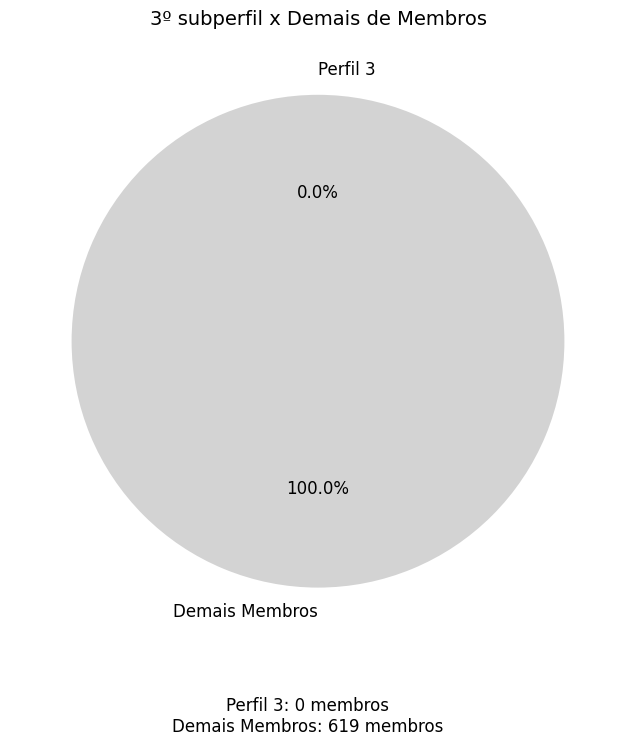

In [ ]:
perfil_3 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Filiação Renovada') &
    (membro_ativo['Chapter Auto Renew Status'] == 'Off') &
    (membro_ativo['Certification Status for Person'] == 'Desconhecida') &
    (membro_ativo['Antiguidade (anos)'].between(1, 5))
]

perfil_count = len(perfil_3)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Perfil 3', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("3º subperfil x Demais de Membros", fontsize=14)

plt.figtext(
    0.5,
    0.01,
    f"Perfil 3: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

<ipython-input-75-ca8750d7ab9c>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  membros_filtrados['Antiguidade (Categoria)'] = pd.cut(


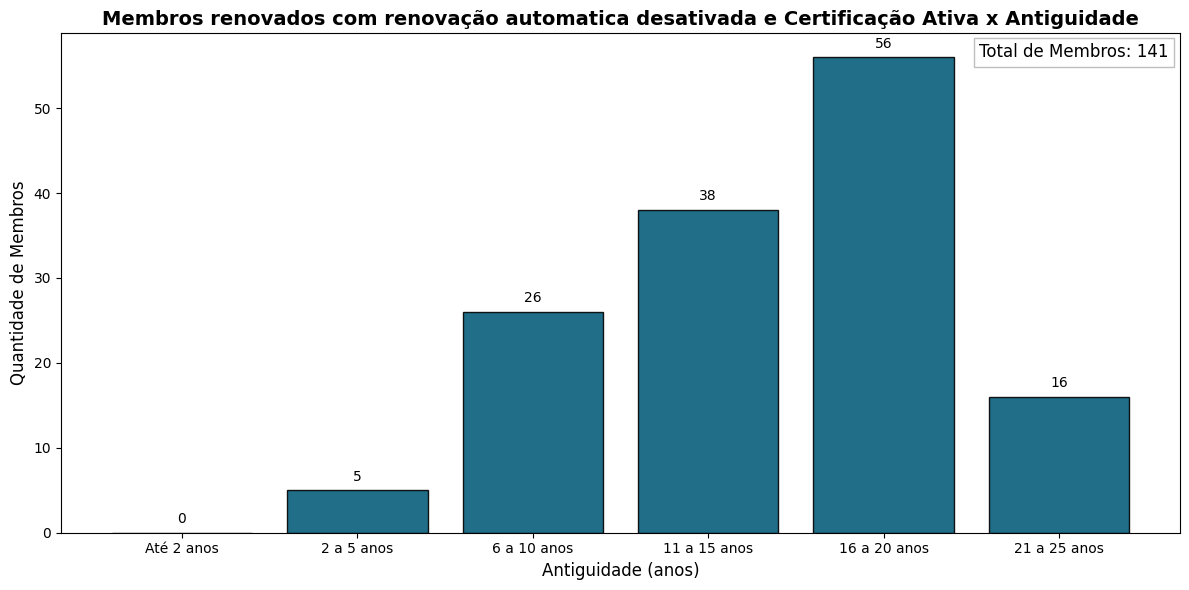

In [ ]:
membros_filtrados = membros_renovados[
    (membros_renovados['Chapter Auto Renew Status'] == 'Off') &
    (membros_renovados['Certification Status for Person'] == 'Ativa')
]

bins = [0, 2, 5, 10, 15, 20, 25]
labels = ['Até 2 anos', '2 a 5 anos', '6 a 10 anos', '11 a 15 anos', '16 a 20 anos', '21 a 25 anos']

membros_filtrados['Antiguidade (Categoria)'] = pd.cut(
    membros_filtrados['Antiguidade (anos)'], bins=bins, labels=labels, include_lowest=True
)

antiguidade_grouped = membros_filtrados['Antiguidade (Categoria)'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
bars = plt.bar(antiguidade_grouped.index, antiguidade_grouped.values, color='#085e7b', alpha=0.9, edgecolor='black')

plt.title("Membros renovados com renovação automatica desativada e Certificação Ativa x Antiguidade", fontsize=14, fontweight='bold')
plt.xlabel("Antiguidade (anos)", fontsize=12)
plt.ylabel("Quantidade de Membros", fontsize=12)

for bar, value in zip(bars, antiguidade_grouped.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + max(antiguidade_grouped.values) * 0.02, str(value), fontsize=10, ha='center', color='black')

total_grouped = antiguidade_grouped.sum()
plt.text(
    0.99,
    0.98,
    f"Total de Membros: {total_grouped}",
    fontsize=12,
    ha='right',
    va='top',
    transform=plt.gca().transAxes,
    bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray')
)

plt.tight_layout()
plt.show()

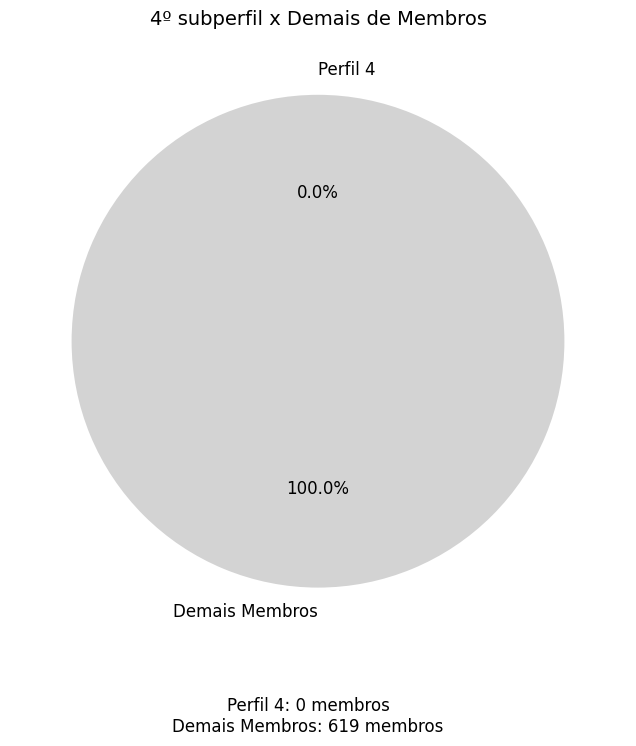

In [ ]:
perfil_4 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Filiação Renovada') &
    (membro_ativo['Chapter Auto Renew Status'] == 'Off') &
    (membro_ativo['Certification Status for Person'] == 'Ativa') &
    (membro_ativo['Antiguidade (anos)'].between(6, 20))
]

perfil_count = len(perfil_4)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Perfil 4', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("4º subperfil x Demais de Membros", fontsize=14)

plt.figtext(
    0.5,
    0.01,
    f"Perfil 4: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

# MEMBROS QUE ESTÃO NO Filiação Inicial

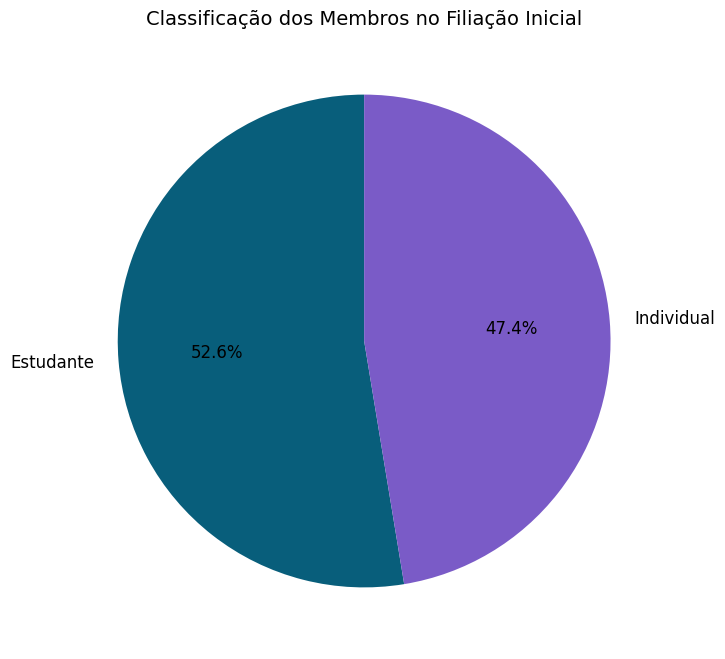

In [ ]:
membros_primeiro_ano = membro_ativo[membro_ativo['Ciclo de Filiação'] == 'Filiação Inicial']

classificacao_counts = membros_primeiro_ano['Chapter Membership Classification'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    classificacao_counts.values,
    labels=classificacao_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', '#7a5bc7', '#ff9166'],
    textprops={'fontsize': 12}
)

plt.title("Classificação dos Membros no Filiação Inicial", fontsize=14)
plt.show()


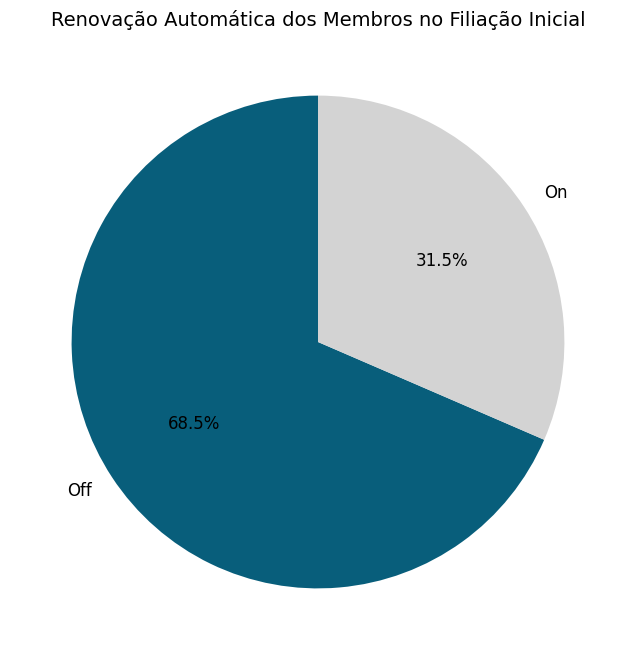

In [ ]:
renovacao_counts = membros_primeiro_ano['Chapter Auto Renew Status'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    renovacao_counts.values,
    labels=renovacao_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("Renovação Automática dos Membros no Filiação Inicial", fontsize=14)
plt.show()


PERFIL GERAL 3 - ESTUDANTE SEM RENOVAÇÃO AUTOMATICA ATIVADA

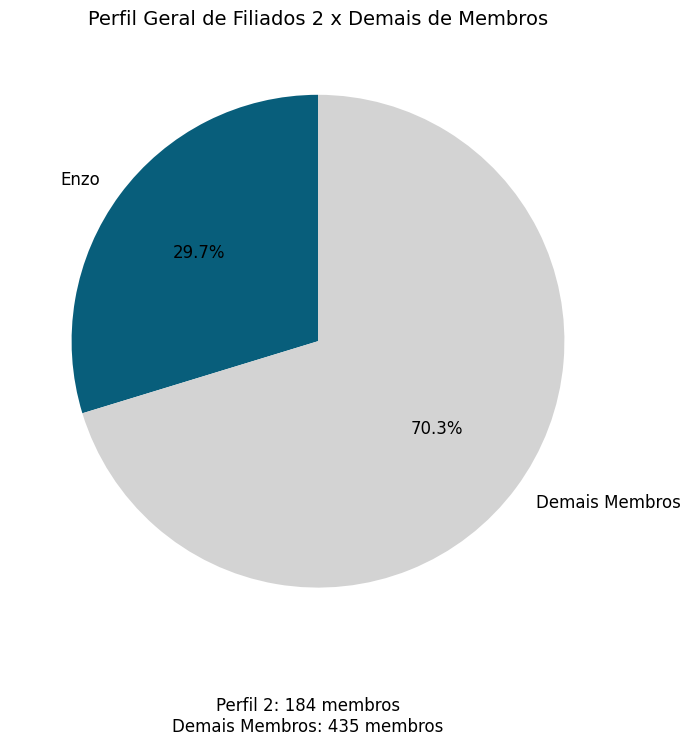

In [ ]:
perfil_5 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Filiação Inicial') &
    (membro_ativo['Chapter Auto Renew Status'] == 'Off')&
    (membro_ativo['Certification Status for Person'] != 'Ativa')
]

perfil_count = len(perfil_5)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Enzo', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("Perfil Geral de Filiados 2 x Demais de Membros", fontsize=14)

plt.figtext(
    0.5,
    0.01,
    f"Perfil 2: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

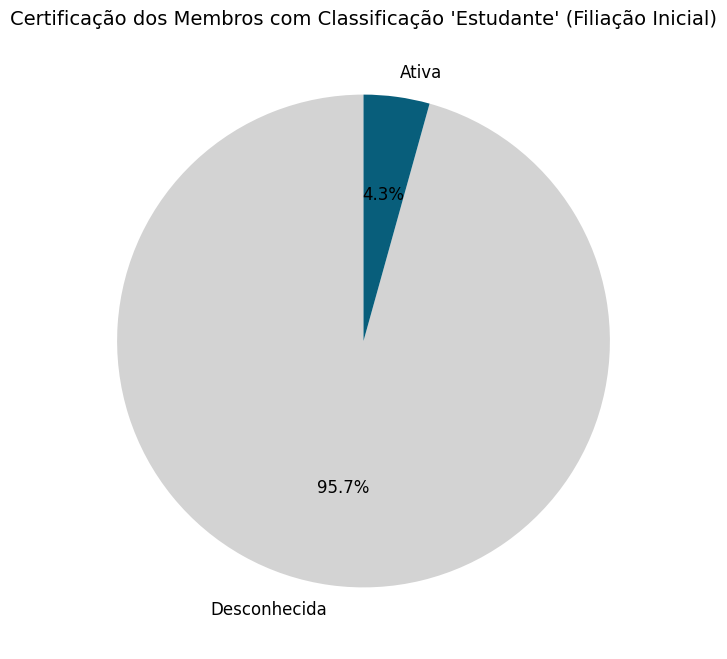

In [ ]:
membros_Estudante = membros_primeiro_ano[membros_primeiro_ano['Chapter Membership Classification'] == 'Estudante']

certificacao_counts = membros_Estudante['Certification Status for Person'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    certificacao_counts.values,
    labels=certificacao_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightgray', '#085e7b'],
    textprops={'fontsize': 12}
)

plt.title("Certificação dos Membros com Classificação 'Estudante' (Filiação Inicial)", fontsize=14)
plt.show()

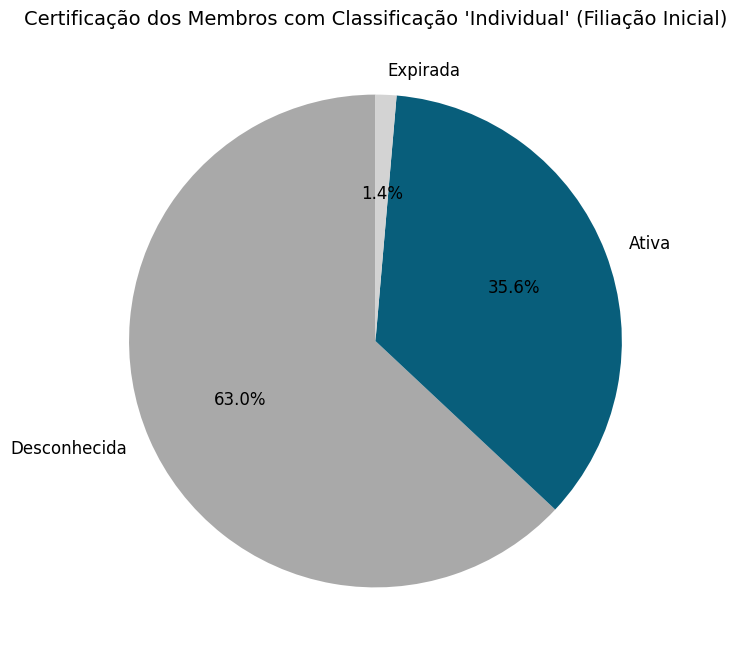

In [ ]:
membros_individual = membros_primeiro_ano[membros_primeiro_ano['Chapter Membership Classification'] == 'Individual']

certificacao_counts = membros_individual['Certification Status for Person'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    certificacao_counts.values,
    labels=certificacao_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['darkgray', '#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("Certificação dos Membros com Classificação 'Individual' (Filiação Inicial)", fontsize=14)
plt.show()

<ipython-input-82-1d6ad69bad89>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  membros_primeiro_ano['Mês/Ano de Filiação'] = membros_primeiro_ano['Chapter Join Date'].dt.strftime('%b/%y').str.capitalize()
<ipython-input-82-1d6ad69bad89>:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  ordem_meses = pd.date_range('2023-11-01', '2024-10-31', freq='M').strftime('%b/%y').str.capitalize()


NameError: name 'media_individual' is not defined

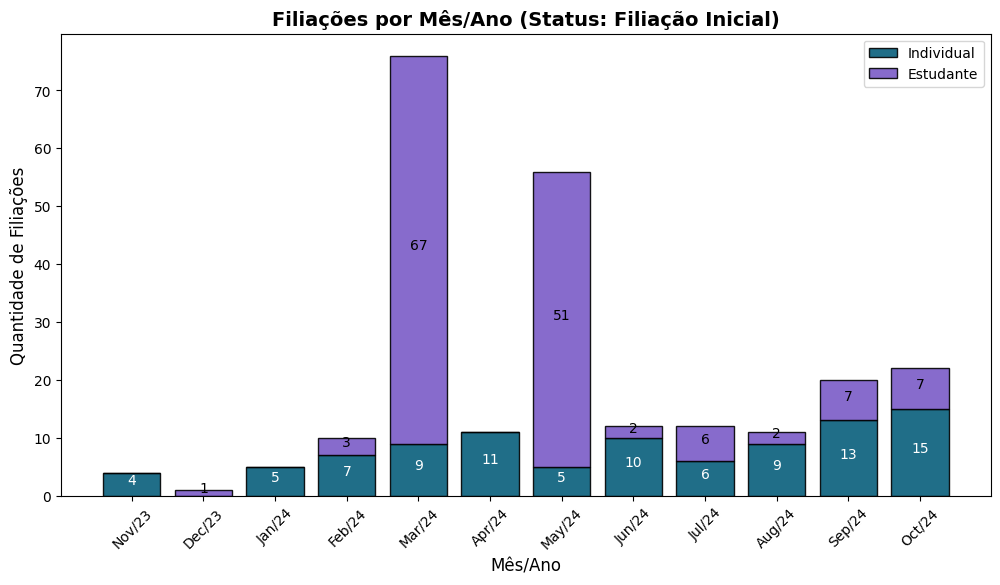

In [ ]:
membros_primeiro_ano = membro_ativo[membro_ativo['Ciclo de Filiação'] == 'Filiação Inicial']
membros_primeiro_ano['Mês/Ano de Filiação'] = membros_primeiro_ano['Chapter Join Date'].dt.strftime('%b/%y').str.capitalize()

#ajutar mes e ano para forma dinamica
ordem_meses = pd.date_range('2023-11-01', '2024-10-31', freq='M').strftime('%b/%y').str.capitalize()

membros_individual = membros_primeiro_ano[membros_primeiro_ano['Chapter Membership Classification'] == 'Individual']
membros_Estudante = membros_primeiro_ano[membros_primeiro_ano['Chapter Membership Classification'] == 'Estudante']

individual_por_mes = (
    membros_individual['Mês/Ano de Filiação']
    .value_counts()
    .reindex(ordem_meses, fill_value=0)
)

Estudante_por_mes = (
    membros_Estudante['Mês/Ano de Filiação']
    .value_counts()
    .reindex(ordem_meses, fill_value=0)
)

# Excluir os meses específicos antes de calcular a média de Estudante
meses_excluir = ['Mar/24', 'May/24', 'Dec/23']
Estudante_por_mes_sem_excluir = Estudante_por_mes[~Estudante_por_mes.index.isin(meses_excluir)]

# Recalcular a média sem os meses excluídos
media_Estudante_ajustada = Estudante_por_mes_sem_excluir.mean()

# Criar o gráfico
plt.figure(figsize=(12, 6))
bars_individual = plt.bar(
    individual_por_mes.index,
    individual_por_mes.values,
    color='#085e7b',
    alpha=0.9,
    edgecolor='black',
    label='Individual'
)

bars_Estudante = plt.bar(
    Estudante_por_mes.index,
    Estudante_por_mes.values,
    bottom=individual_por_mes.values,
    color='#7a5bc7',
    alpha=0.9,
    edgecolor='black',
    label='Estudante'
)

plt.title("Filiações por Mês/Ano (Status: Filiação Inicial)", fontsize=14, fontweight='bold')
plt.xlabel("Mês/Ano", fontsize=12)
plt.ylabel("Quantidade de Filiações", fontsize=12)
plt.xticks(ticks=range(len(ordem_meses)), labels=ordem_meses, fontsize=10, rotation=45)
plt.legend()

for i, (ind, stu) in enumerate(zip(individual_por_mes.values, Estudante_por_mes.values)):
    if ind > 0:
        plt.text(i, ind / 2, str(ind), ha='center', fontsize=10, color='white')
    if stu > 0:
        plt.text(i, ind + stu / 2, str(stu), ha='center', fontsize=10, color='black')

# Adicionar observação com as médias abaixo do gráfico
observacoes = f"Média de Individual: {media_individual:.1f}\nMédia de Estudante (Retirando os Picos): {media_Estudante_ajustada:.1f}"
plt.figtext(
    0.5,
    -0.1,
    observacoes,
    wrap=True,
    horizontalalignment='center',
    fontsize=10,
    color='black'
)

plt.tight_layout()
plt.show()


In [ ]:
membros_renovacao_on = membros_primeiro_ano[membros_primeiro_ano['Chapter Auto Renew Status'] == 'Off']

classificacao_counts = membros_renovacao_on['Chapter Membership Classification'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    classificacao_counts.values,
    labels=classificacao_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("Classificação dos Membros com Renovação Automática Desativada (Filiação Inicial)", fontsize=14)
plt.show()


ESTUDANTE COM RENOVAÇÃO AUTOMATICA DESATIVADA SEM CERTIFICAÇÃO

In [ ]:
perfil_5 = membro_ativo[
    (membro_ativo['Ciclo de Filiação'] == 'Filiação Inicial') &
    (membro_ativo['Chapter Auto Renew Status'] == 'Off') &
    (membro_ativo['Certification Status for Person'] == 'Desconhecida')
]

perfil_count = len(perfil_5)
total_count = len(membro_ativo)

values = [perfil_count, total_count - perfil_count]
labels = ['Perfil 5', 'Demais Membros']


plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)

plt.title("5º subperfil x Demais de Membros", fontsize=14)

plt.figtext(
    0.5,
    0.01,
    f"Perfil 5: {perfil_count} membros\nDemais Membros: {total_count - perfil_count} membros",
    wrap=True,
    horizontalalignment='center',
    fontsize=12
)

plt.show()

In [ ]:
expiracoes_2025 = membro_ativo[
    (membro_ativo['Chapter Expiration Date'].dt.year == 2025) &
    (membro_ativo['Chapter Auto Renew Status'] == 'Off')
]

expiracoes_2025['Mês de Expiração'] = expiracoes_2025['Chapter Expiration Date'].dt.month
expiracoes_por_mes = expiracoes_2025.groupby('Mês de Expiração').size()

meses_nomeados = ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho',
                  'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']

cores = ['lightgray' if mes not in [3, 5] else '#085e7b' for mes in expiracoes_por_mes.index]

plt.figure(figsize=(12, 6))
plt.bar([meses_nomeados[mes - 1] for mes in expiracoes_por_mes.index],
        expiracoes_por_mes.values, color=cores, edgecolor='black')

plt.title("Expirações Previstas para 2025 por Mês", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Quantidade de Expirações", fontsize=12)

for i, valor in enumerate(expiracoes_por_mes.values):
    plt.text(i, valor + 0.2, str(valor), ha='center', fontsize=10, color='black')

plt.figtext(0.1, -0.1, "Observação: Apenas membros que não possuem renovação automática estão incluídos.",
            wrap=True, horizontalalignment='center', fontsize=10, color='black')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
len(expiracoes_2025)

# ANALISE NÃO RENOVADOS

In [ ]:
email_counts = n_renovados['Receive Electronic Notification'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    email_counts.values,
    labels=email_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    textprops={'fontsize': 12}
)


plt.title("Notificações Eletrônicas Enviadas para Membros Expirados em Nov/2024", fontsize=14)
plt.show()

In [ ]:
n_renovados['PMP Status'] = n_renovados['PMP Status'].fillna('Not Certified')

status_certificacao = n_renovados['PMP Status'].value_counts()

cores = ['#085e7b', 'lightgray', 'lightcoral', 'lightgreen']
plt.figure(figsize=(8, 8))
status_certificacao.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=cores,
    title="Proporção de Certificados dos Não Renovados no Mês Anterior"
)
plt.ylabel('')
plt.show()

In [ ]:
n_renovados['Industry Type'] = n_renovados['Industry Type'].fillna('Indefinido')

industry_counts = n_renovados['Industry Type'].value_counts()

plt.figure(figsize=(12, 6))
industry_counts.plot(kind='bar', color='#085e7b', edgecolor='black')
plt.title("Distribuição dos Tipos de Indústria dos Desfiliados", fontsize=14, fontweight='bold')
plt.xlabel("Tipo de Indústria", fontsize=12)
plt.ylabel("Quantidade", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
status_renovacao = renovados['Chapter Auto Renew Status'].value_counts()

plt.figure(figsize=(8, 8))
status_renovacao.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=['#085e7b', 'lightgray'],
    title="Status da Renovação Automática (Renovados)"
)
plt.ylabel('')
plt.show()